# 02 · Denoising the accelerometer signal: 20k rpm run

Uses `denoise.py`. The rule is: **remove only what notebook 01 identified as background in the no-cutting segment, and nothing else.**

| Step | Removes | Why it is safe |
|---|---|---|
| 1. Despike (6× the local 10 ms level, replaced by an 11-sample median) | single-sample electrical glitches, mostly on Z | a real vibration cannot appear and vanish within one sample |
| 2. High-pass, 50 Hz | mean, slow drift (mainly Y) and a few weak machine lines below 50 Hz | the lowest spindle frequency in the tests is 333 Hz; nothing from cutting is expected below 50 Hz |
| 3. Narrow line removal | mains 50 Hz multiples and the 4.466 Hz comb, both only up to 400 Hz | 47 Hz of bandwidth in total, out of 10,000 Hz |

**Not touched:** the flat broadband floor, the spindle lines (333 / 667 Hz), the Y hump near 4.9 kHz, and everything above 400 Hz.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from scipy import signal, stats
from pathlib import Path
import denoise as dn

FS = dn.FS
AX = ['X (feed)', 'Y (normal to feed)', 'Z (axial)']
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
BEFORE, AFTER, REMOVED = '#2a78d6', '#eb6834', '#1baf7a'   # blue, orange, aqua
INK, MUTED = '#0b0b0b', '#898781'
plt.rcParams.update({'figure.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.6,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.labelcolor': '#52514e',
                     'axes.titlesize': 11, 'axes.titleweight': 'bold', 'font.size': 10})

t, x = dn.load_lvm('Acce_20k_1_r1.lvm')
y, info = dn.denoise(x)
x0 = x - x[:20*FS].mean(0)          # 'before', with the no-cutting mean taken off so the two share a zero
print('bandwidth removed by line removal: %.0f Hz of %d Hz' % (info[0]['removed_bandwidth_hz'], FS//2))
SEG = {'no cutting 0–20 s': (0, 20), 'cutting 30–39 s': (30, 39), 'cutting 42–51 s': (42, 51), 'after cut 53–60 s': (53, 60)}
def psd(v, nper=2*FS): return signal.welch(v - v.mean(), FS, nperseg=nper, noverlap=nper//2)

bandwidth removed by line removal: 47 Hz of 10000 Hz


## 1. Time signal, no cutting: before, after, and what was removed

A short 0.1 s window (5.20–5.30 s), one panel each so nothing is drawn on top of anything else. Each row shares one vertical scale. The right-hand column is simply *before − after*: it is exactly what the denoiser took out.

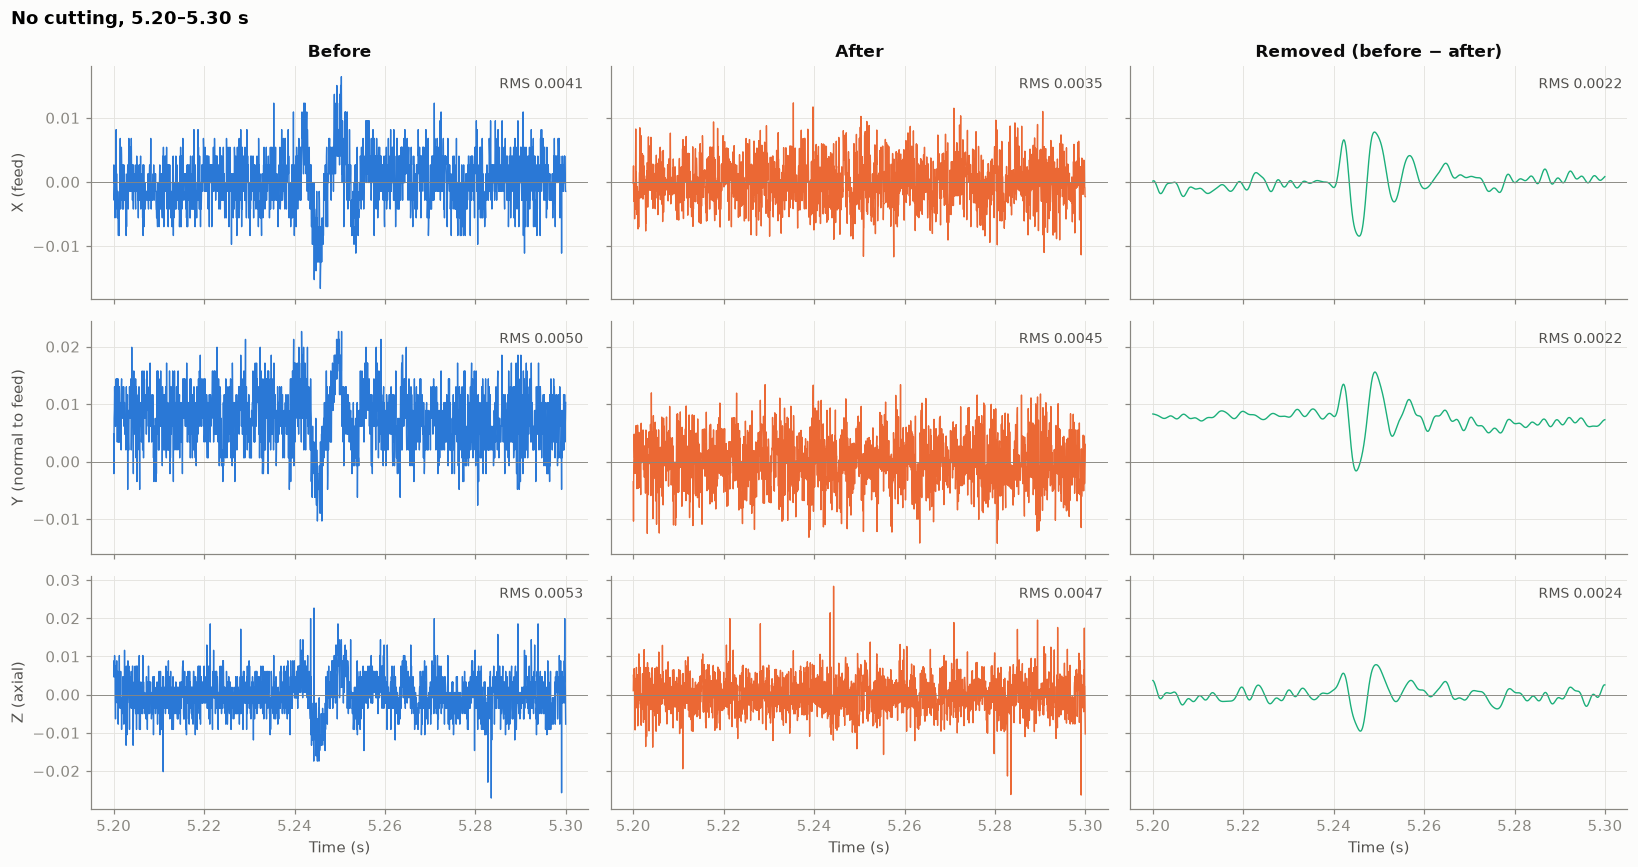

In [2]:
z = slice(int(5.20*FS), int(5.30*FS))
fig, ax = plt.subplots(3, 3, figsize=(15, 8), sharex=True, sharey='row')
for i in range(3):
    for j, (v, c, name) in enumerate([(x0[z,i], BEFORE, 'Before'), (y[z,i], AFTER, 'After'), (x0[z,i]-y[z,i], REMOVED, 'Removed (before − after)')]):
        ax[i,j].plot(t[z], v, lw=0.9, color=c)
        ax[i,j].axhline(0, color=MUTED, lw=0.6)
        if i == 0: ax[i,j].set_title(name, color=INK)
        ax[i,j].text(0.99, 0.95, f'RMS {v.std():.4f}', transform=ax[i,j].transAxes, ha='right', va='top', color='#52514e', fontsize=9)
    ax[i,0].set_ylabel(AX[i])
for a in ax[2]: a.set_xlabel('Time (s)')
fig.suptitle('No cutting, 5.20–5.30 s', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.savefig(FIG/'02a_time_no_cutting.png'); plt.show()

## 2. Slow drift, no cutting

The same signals averaged over 0.1 s, so only the slow movement is left. This is where the Y drift shows.

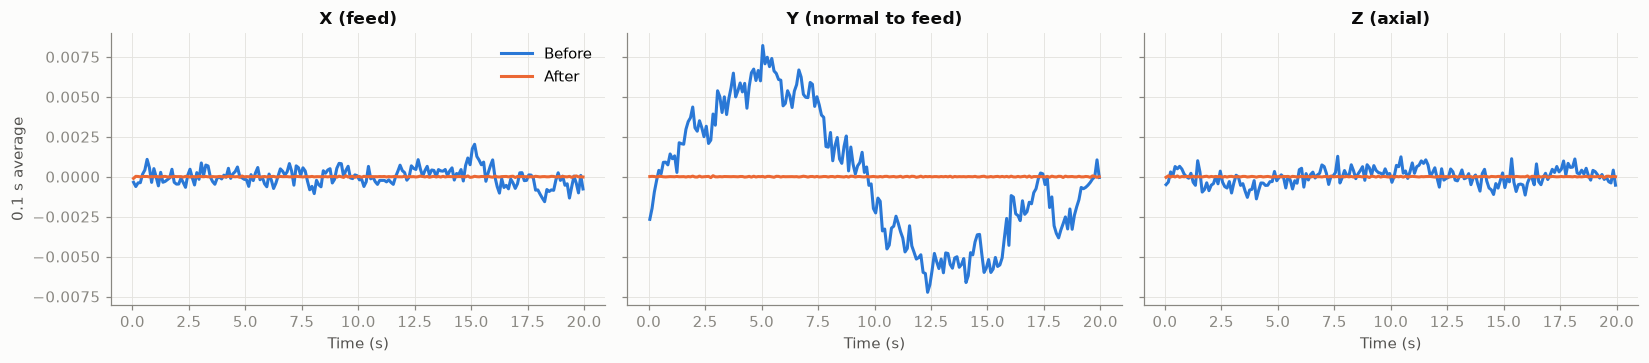

In [3]:
w = int(0.1*FS); nb_ = 20*FS//w; tt = (np.arange(nb_) + 0.5)*w/FS
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4), sharey=True)
for i in range(3):
    ax[i].plot(tt, x0[:nb_*w,i].reshape(nb_, w).mean(1), lw=2, color=BEFORE, label='Before')
    ax[i].plot(tt, y[:nb_*w,i].reshape(nb_, w).mean(1), lw=2, color=AFTER, label='After')
    ax[i].set_title(AX[i], color=INK); ax[i].set_xlabel('Time (s)')
ax[0].set_ylabel('0.1 s average'); ax[0].legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG/'02b_drift_no_cutting.png'); plt.show()

## 3. Spectrum, no cutting: before and after

0–450 Hz, which is the only range the denoiser acts on. Left and right share the same scale.

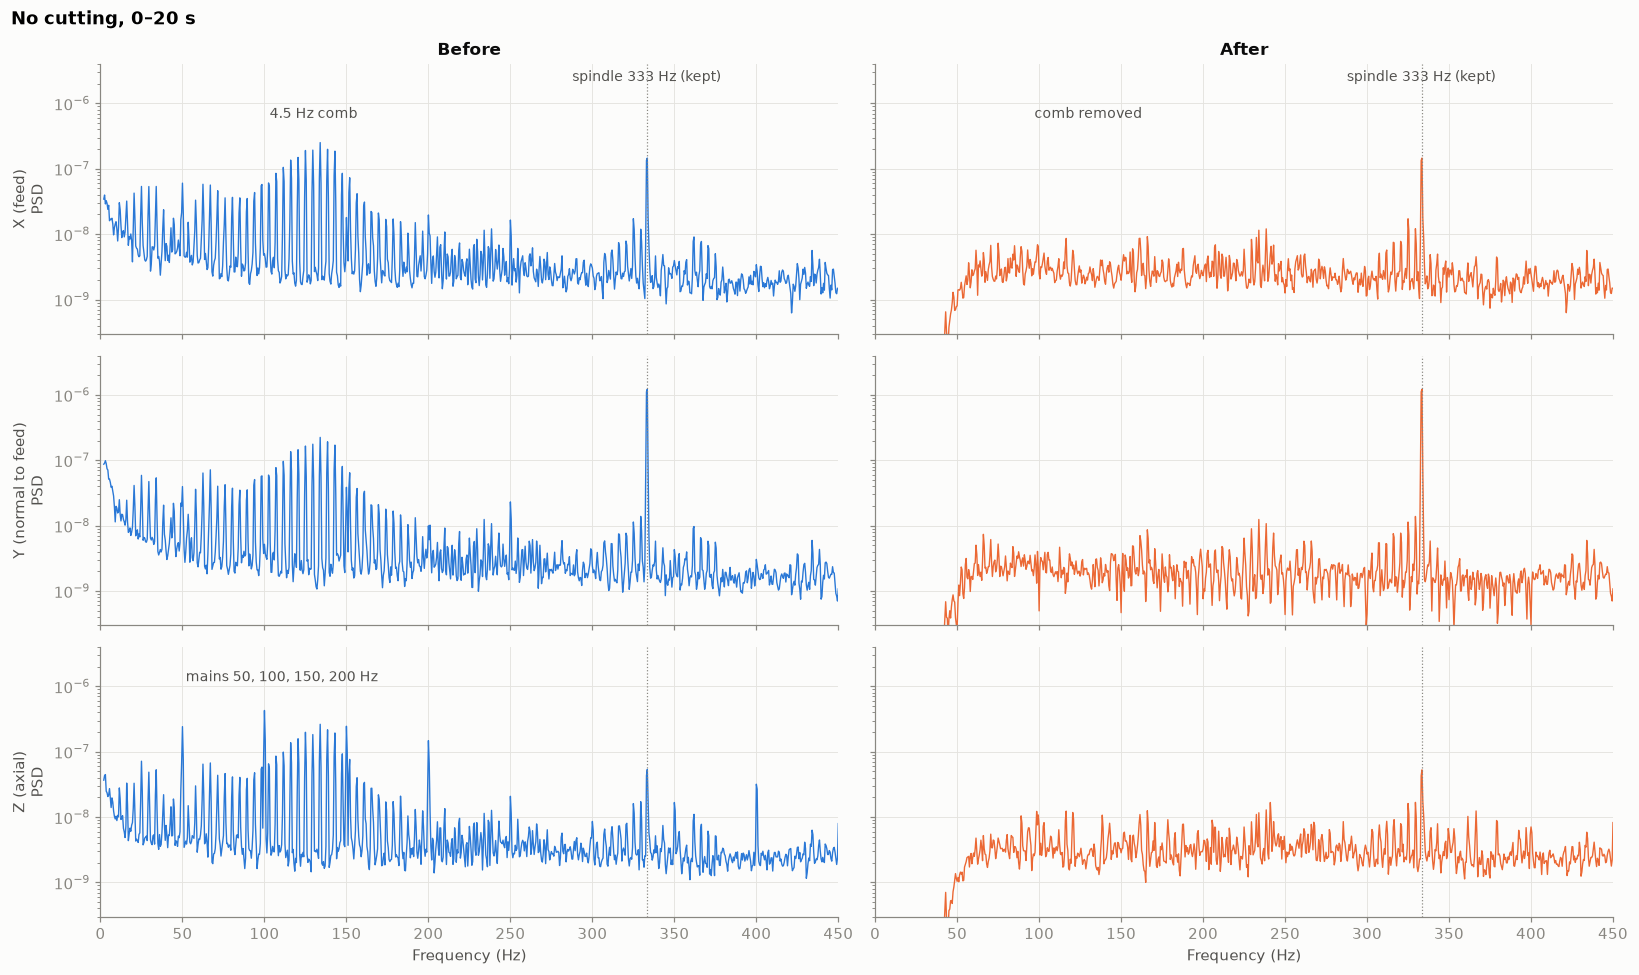

In [4]:
pre = slice(0, 20*FS)
fig, ax = plt.subplots(3, 2, figsize=(15, 9), sharex=True, sharey=True)
for i in range(3):
    f, P = psd(x0[pre,i]); _, Q = psd(y[pre,i]); m = (f >= 2) & (f <= 450)
    ax[i,0].semilogy(f[m], P[m], lw=0.9, color=BEFORE); ax[i,1].semilogy(f[m], Q[m], lw=0.9, color=AFTER)
    ax[i,0].set_ylabel(AX[i] + '\nPSD')
    for a in ax[i]: a.axvline(333.33, color=MUTED, lw=0.8, ls=':')
ax[0,0].set_title('Before', color=INK); ax[0,1].set_title('After', color=INK)
ax[0,0].set_ylim(3e-10, 4e-6); ax[0,0].set_xlim(0, 450)
note = dict(color='#52514e', fontsize=9, ha='center')
ax[0,0].text(130, 6e-7, '4.5 Hz comb', **note); ax[0,0].text(333, 2.2e-6, 'spindle 333 Hz (kept)', **note)
ax[0,1].text(333, 2.2e-6, 'spindle 333 Hz (kept)', **note); ax[0,1].text(130, 6e-7, 'comb removed', **note)
ax[2,0].text(52, 1.2e-6, 'mains 50, 100, 150, 200 Hz', color='#52514e', fontsize=9, ha='left')
for a in ax[2]: a.set_xlabel('Frequency (Hz)')
fig.suptitle('No cutting, 0–20 s', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.savefig(FIG/'02c_spectrum_no_cutting.png'); plt.show()

## 4. Spectrum during cutting: is anything lost?

Cutting stretch 30–39 s, full band. The third column is *after ÷ before* in percent: 100 % means untouched.

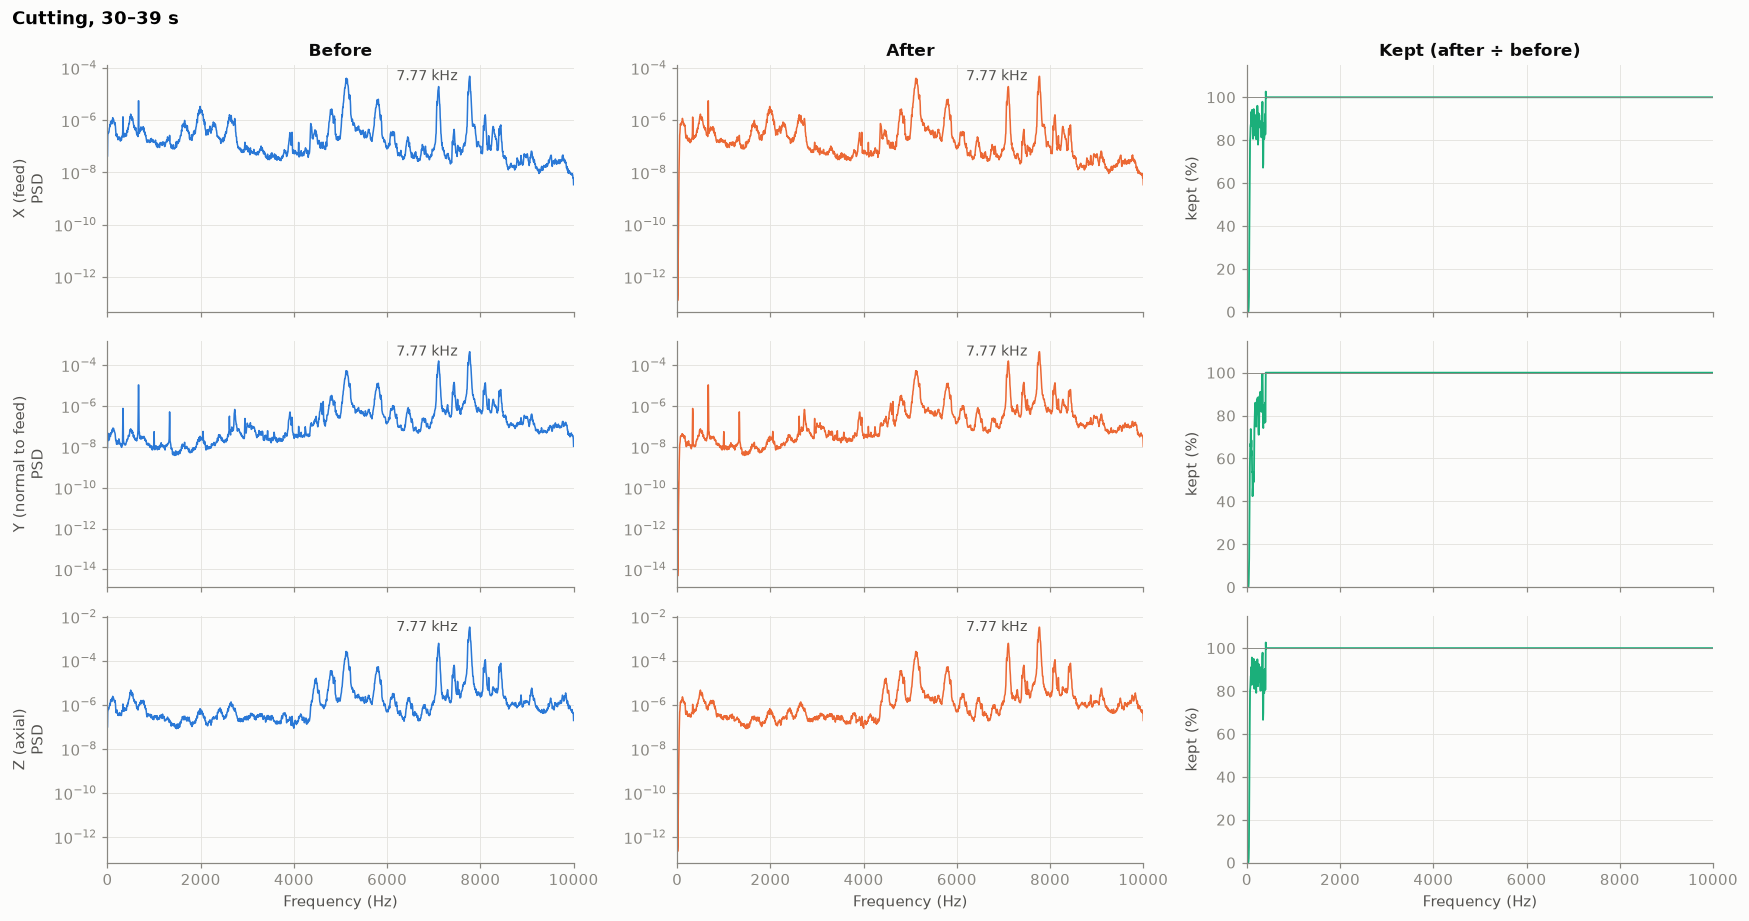

In [5]:
cut = slice(30*FS, 39*FS)
fig, ax = plt.subplots(3, 3, figsize=(16, 8.5), sharex=True)
for i in range(3):
    f, P = psd(x0[cut,i], 4096); _, Q = psd(y[cut,i], 4096)
    ax[i,0].semilogy(f, P, lw=1.0, color=BEFORE); ax[i,1].semilogy(f, Q, lw=1.0, color=AFTER)
    ax[i,1].sharey(ax[i,0])
    ax[i,2].plot(f[1:], 100*Q[1:]/P[1:], lw=1.2, color=REMOVED); ax[i,2].set_ylim(0, 115); ax[i,2].axhline(100, color=MUTED, lw=0.6)
    k = np.argmax(P)
    for a in ax[i,:2]: a.annotate(f'{f[k]/1000:.2f} kHz', (f[k], P[k]), xytext=(-8, 0), textcoords='offset points', ha='right', va='center', color='#52514e', fontsize=9)
    ax[i,0].set_ylabel(AX[i] + '\nPSD'); ax[i,2].set_ylabel('kept (%)')
ax[0,0].set_title('Before', color=INK); ax[0,1].set_title('After', color=INK); ax[0,2].set_title('Kept (after ÷ before)', color=INK)
for a in ax[2]: a.set_xlabel('Frequency (Hz)')
ax[0,0].set_xlim(0, FS/2)
fig.suptitle('Cutting, 30–39 s', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.savefig(FIG/'02d_spectrum_cutting.png'); plt.show()

## 5. Summary in three bar charts

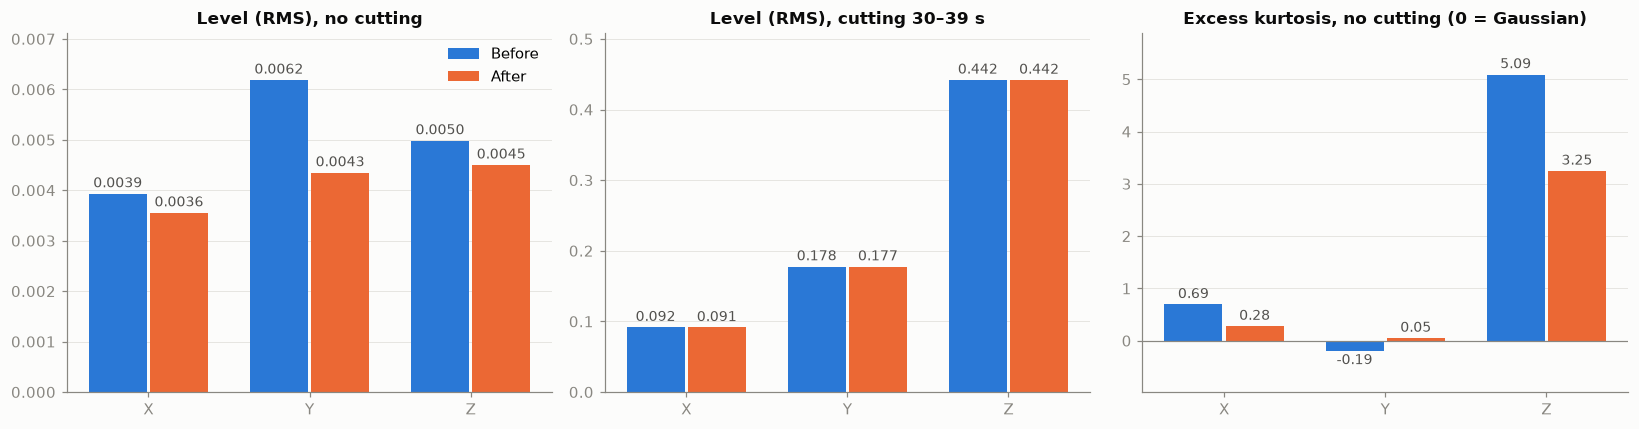

In [6]:
def bars(a, before, after, title, fmt):
    xs = np.arange(3); w = 0.36
    b1 = a.bar(xs - w/2 - 0.01, before, w, color=BEFORE, label='Before'); b2 = a.bar(xs + w/2 + 0.01, after, w, color=AFTER, label='After')
    a.bar_label(b1, fmt=fmt, color='#52514e', fontsize=9, padding=2); a.bar_label(b2, fmt=fmt, color='#52514e', fontsize=9, padding=2)
    a.set_xticks(xs, ['X', 'Y', 'Z']); a.set_title(title, color=INK); a.grid(axis='x', visible=False); a.margins(y=0.15)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
p, c = slice(0, 20*FS), slice(30*FS, 39*FS)
bars(ax[0], x0[p].std(0), y[p].std(0), 'Level (RMS), no cutting', '%.4f')
bars(ax[1], (x0[c]-x0[c].mean(0)).std(0), y[c].std(0), 'Level (RMS), cutting 30–39 s', '%.3f')
bars(ax[2], stats.kurtosis(x0[p]), stats.kurtosis(y[p]), 'Excess kurtosis, no cutting (0 = Gaussian)', '%.2f')
ax[2].axhline(0, color=MUTED, lw=0.8); ax[0].legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG/'02e_summary_bars.png'); plt.show()

## 5b. Time signal 25–40 s: before, after, removed

This stretch covers the gradual rise after tool entry, the steep rise near 30–34 s and the drop near 39 s. Each panel shows the signal's range (min to max) in 20 ms slices, so the shape is readable. All three columns in a row share one vertical scale. The removed column is *before − after*.

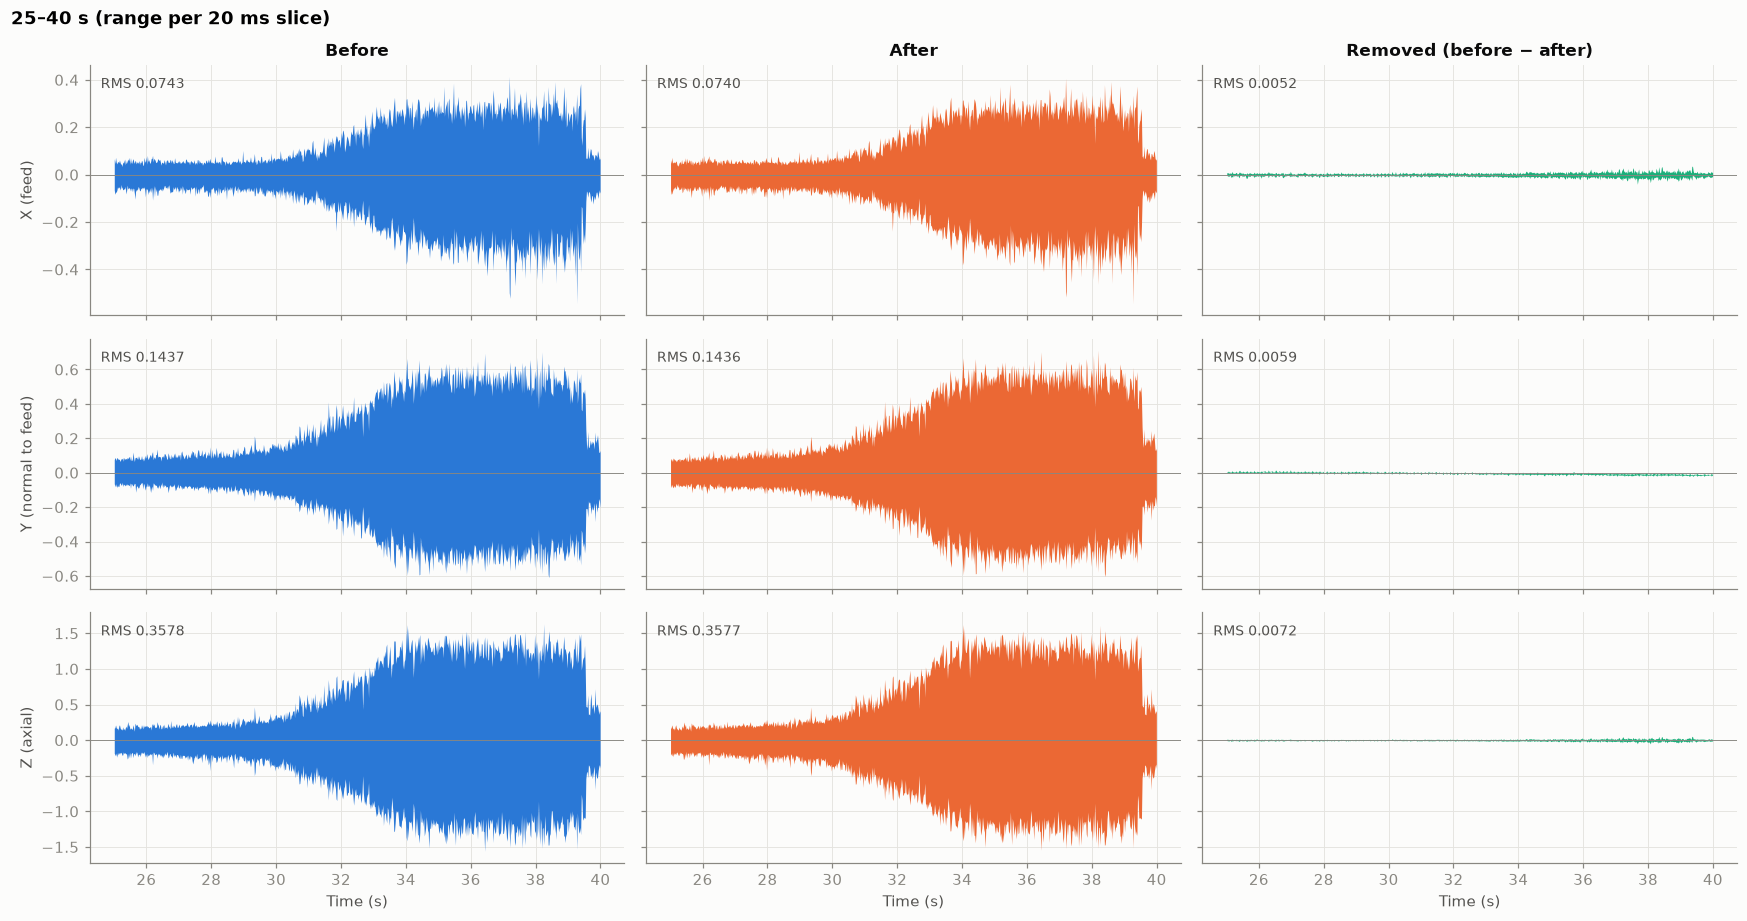

In [7]:
a, b = 25, 40; s = slice(a*FS, b*FS); w = int(0.02*FS); nw = (b-a)*FS//w; tw = a + (np.arange(nw) + 0.5)*w/FS
fig, ax = plt.subplots(3, 3, figsize=(16, 8.5), sharex=True, sharey='row')
for i in range(3):
    for j, (v, c, name) in enumerate([(x0[s,i], BEFORE, 'Before'), (y[s,i], AFTER, 'After'), (x0[s,i]-y[s,i], REMOVED, 'Removed (before − after)')]):
        blk = v[:nw*w].reshape(nw, w)
        ax[i,j].fill_between(tw, blk.min(1), blk.max(1), color=c, lw=0)
        ax[i,j].axhline(0, color=MUTED, lw=0.6)
        if i == 0: ax[i,j].set_title(name, color=INK)
        ax[i,j].text(0.02, 0.95, f'RMS {v.std():.4f}', transform=ax[i,j].transAxes, ha='left', va='top', color='#52514e', fontsize=9)
    ax[i,0].set_ylabel(AX[i])
for q in ax[2]: q.set_xlabel('Time (s)')
fig.suptitle('25–40 s (range per 20 ms slice)', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.savefig(FIG/'02f_time_25-40s.png'); plt.show()

The same comparison as running level (RMS in 0.1 s windows, log scale), which shows the small early part of the stretch as clearly as the large part.

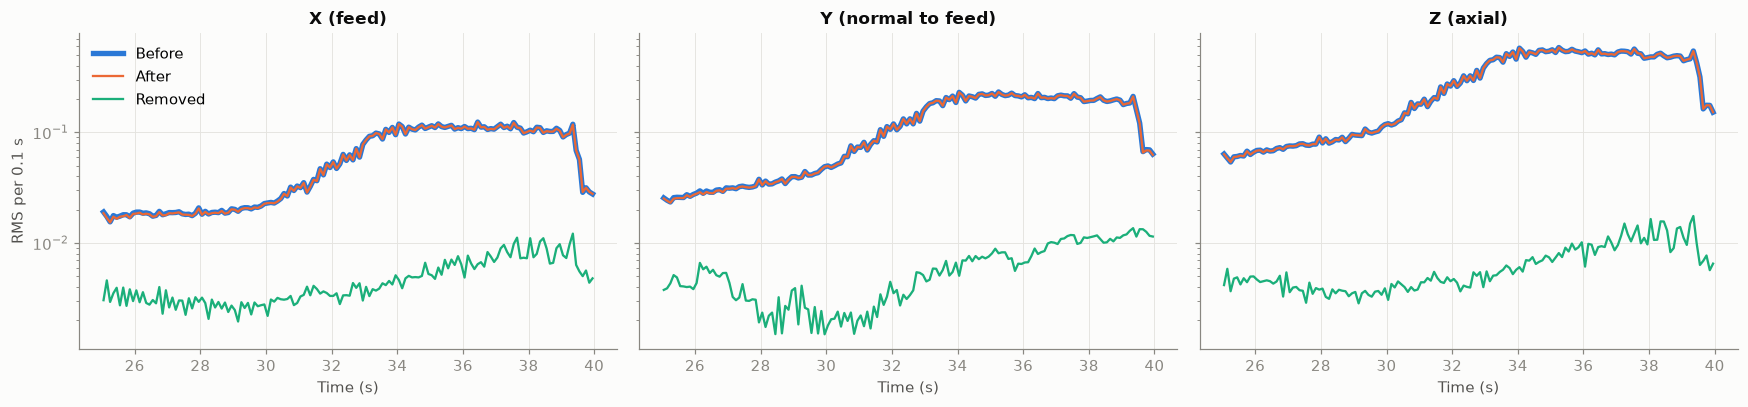

X (feed)             RMS before 0.0743  after 0.0740  removed 0.0052  = 0.50% of the energy
Y (normal to feed)   RMS before 0.1437  after 0.1436  removed 0.0059  = 0.17% of the energy
Z (axial)            RMS before 0.3578  after 0.3577  removed 0.0072  = 0.04% of the energy


In [8]:
w = int(0.1*FS); nw = (b-a)*FS//w; tw = a + (np.arange(nw) + 0.5)*w/FS
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for i in range(3):
    rms = lambda v: np.sqrt((v[:nw*w].reshape(nw, w)**2).mean(1))
    ax[i].semilogy(tw, rms(x0[s,i]), lw=3.5, color=BEFORE, label='Before')
    ax[i].semilogy(tw, rms(y[s,i]), lw=1.5, color=AFTER, label='After')
    ax[i].semilogy(tw, rms(x0[s,i]-y[s,i]), lw=1.5, color=REMOVED, label='Removed')
    ax[i].set_title(AX[i], color=INK); ax[i].set_xlabel('Time (s)')
ax[0].set_ylabel('RMS per 0.1 s'); ax[0].legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.savefig(FIG/'02g_level_25-40s.png'); plt.show()
for i in range(3):
    u, v = x0[s,i], y[s,i]
    print(f"{AX[i]:20s} RMS before {u.std():.4f}  after {v.std():.4f}  removed {(u-v).std():.4f}  = {100*(u-v).var()/u.var():.2f}% of the energy")

## 6. Numbers: what changed in each part of the record

- **RMS change:** how much the signal level dropped.
- **Excess kurtosis:** 0 = Gaussian.
- **Samples replaced:** by the despiker.
- **Dominant peak kept:** power at the strongest spectral peak above 1 kHz, after ÷ before.
- **Power kept above 400 Hz:** after ÷ before.

In [9]:
print(f"{'segment':20s}{'axis':>5s}{'RMS before':>12s}{'RMS after':>11s}{'change':>8s}{'kurt before':>12s}{'kurt after':>11s}{'replaced':>10s}{'peak (Hz)':>11s}{'peak kept':>10s}{'>400Hz kept':>12s}")
for name, (a, b) in SEG.items():
    s = slice(a*FS, b*FS)
    for i in range(3):
        u = x[s,i] - x[s,i].mean(); v = y[s,i]
        f, P = psd(u); _, Q = psd(v)
        hi = f > 1000; k = np.flatnonzero(hi)[np.argmax(P[hi])]; m = f > 400
        print(f"{name:20s}{'XYZ'[i]:>5s}{u.std():12.5f}{v.std():11.5f}{100*(v.std()/u.std()-1):7.1f}%{stats.kurtosis(u):12.2f}{stats.kurtosis(v):11.2f}"
              f"{100*info[i]['spike_mask'][s].mean():9.2f}%{f[k]:11.1f}{100*Q[k]/P[k]:9.1f}%{100*Q[m].sum()/P[m].sum():11.1f}%")

segment              axis  RMS before  RMS after  change kurt before kurt after  replaced  peak (Hz) peak kept >400Hz kept
no cutting 0–20 s       X     0.00393    0.00355   -9.6%        0.69       0.28     0.00%     1862.0     99.7%      100.0%
no cutting 0–20 s       Y     0.00619    0.00435  -29.7%       -0.19       0.05     0.00%     3961.0    100.0%      100.0%
no cutting 0–20 s       Z     0.00498    0.00450   -9.7%        5.09       3.25     0.09%     3961.0     99.5%       94.6%


cutting 30–39 s         X     0.09169    0.09144   -0.3%        0.75       0.74     0.00%     7775.5    100.0%      100.0%


cutting 30–39 s         Y     0.17751    0.17746   -0.0%        0.03       0.04     0.00%     7775.5    100.0%      100.0%
cutting 30–39 s         Z     0.44180    0.44170   -0.0%        0.01       0.01     0.00%     7775.5    100.0%      100.0%
cutting 42–51 s         X     0.05229    0.05192   -0.7%       18.56      18.47     0.00%     8178.5    100.0%      100.0%
cutting 42–51 s         Y     0.10603    0.10594   -0.1%        5.01       5.06     0.00%     8178.5    100.0%      100.0%
cutting 42–51 s         Z     0.27680    0.27664   -0.1%        4.72       4.71     0.00%     8178.5    100.0%      100.0%
after cut 53–60 s       X     0.00401    0.00368   -8.1%        0.70       0.26     0.00%     1871.0    100.0%      100.0%
after cut 53–60 s       Y     0.00590    0.00542   -8.1%        0.10       0.03     0.00%     4860.5    100.0%      100.0%
after cut 53–60 s       Z     0.00501    0.00460   -8.2%        4.67       2.97     0.09%     3580.5     99.9%       94.3%


## 7. Findings

**What denoising did to the background (no cutting, 0–20 s)**
- RMS dropped by 10 % on X, 30 % on Y (mostly the drift) and 10 % on Z.
- X and Y are now very close to Gaussian (excess kurtosis 0.28 and 0.05).
- Z improved (excess kurtosis 5.1 → 3.3) but still has clearly heavier tails than a Gaussian. The despiker replaced 0.09 % of Z samples; it is deliberately strict so that it cannot clip real cutting peaks.
- The mains lines, the 4.5 Hz comb and everything below 50 Hz are gone from the spectrum. The spindle lines at 333 and 667 Hz are still there, as intended.
- Most of the background is the flat floor, and that is still there. Denoising this way cannot lower it.

**Does it lose the chatter?** No, as far as this file shows.
- During cutting the signal is dominated by a narrow peak near **7.77 kHz** (30–39 s) and **8.18 kHz** (42–51 s). Neither is a multiple of the spindle frequency (333.3 Hz), which is what chatter looks like. The denoiser only acts below 400 Hz.
- That peak keeps 100 % of its power, and power above 400 Hz is kept at 100 %.
- RMS during cutting changes by 0.0–0.3 % (0.7 % on X in the second cutting stretch), all of it below 400 Hz.
- The despiker replaces essentially no samples during cutting (0.00 %). An earlier version judged spikes against an 11-sample spread and clipped real peaks of the near-Nyquist cutting signal; it now judges them against the level over 10 ms.

**Caveats**
- The dominant cutting frequencies (7.8–8.2 kHz) are close to the 10 kHz limit of a 20 kHz recording. If the acquisition had no anti-aliasing filter, the true frequency could be higher and folded down. Worth checking the DAQ settings, and recording new tests at 50 kHz or more.
- The filters here are zero-phase and use the whole record, so this is offline processing. A live version needs causal filters.
- The comb frequency (4.466 Hz) was measured on this file. It has to be re-checked on the 60k and 100k files.
- Whether the 7.8–8.2 kHz peak is chatter still has to be confirmed against the labels.